# 04 - Cross-validation of Model E

The test set of notebook 03 holds only part of the molecules, drawn at random: its score depends a lot on that draw. Here, **every molecule is tested once**:
1. the molecules are split into 5 groups;
2. Model E is trained on 4 groups and tested on the 5th;
3. this is repeated with each group as the test group, and the whole procedure is repeated with several splits.

This gives a stable score, with its error margin, compared with simple rules on exactly the same molecules. The notebook uses all the molecules prepared by notebook 01 (train + test).

This is the **only** cross-validation of the project: its predictions are saved to `data/processed/cv_predictions.csv` and notebook 05 analyses them.

In [1]:
import sys
from pathlib import Path
# Find the project root (the folder that contains src/config.py) and make src/ importable
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from config import TRAIN, TEST, FIGURES, CV_PREDICTIONS, ensure_dir
import plot_style as ps

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, balanced_accuracy_score

In [2]:
N_FOLDS = 5        # 5-fold cross-validation
N_REPEATS = 3      # number of different splits

In [3]:
# The 16 features of Model E, in Arthur's order (cell 18): the order expected by scripts/predict.py
cols_E = ['MolWt', 'Sol_Dielectric', 'Sol_Hansen_D', 'Sol_Hansen_P', 'Sol_Hansen_H']
vector_cols = [f'Matrix_Vector_{i}' for i in range(1, 11)]
xgb_cols = ['RT'] + cols_E + vector_cols

def make_model_E(scale_weight):
    """Arthur's Model E: same settings as in rt_prediction_continued.ipynb (cell 18)."""
    return xgb.XGBClassifier(n_estimators=1000, learning_rate=0.01, max_depth=4, subsample=0.8,
        colsample_bytree=0.5,colsample_bynode=0.9, gamma=.8, min_child_weight=10, reg_lambda=5, reg_alpha=1,  scale_pos_weight=scale_weight,
        random_state=72, n_jobs=-1)

def rank_per_molecule(df, proba):
    """One row per molecule x solvent: mean predicted probability over the molecule's HPLC columns."""
    g = df[['CAS', 'Solvent_Name', 'Soluble']].assign(p=proba)
    return (g.groupby(['CAS', 'Solvent_Name'], as_index=False).agg(p=('p', 'mean'), y=('Soluble', 'first'))
             .rename(columns={'Solvent_Name': 'Solvent'}))

def first_choices(ranking):
    """For each molecule: the solvent ranked first, and whether that choice was right (the molecule dissolves in it)."""
    rows = []
    for cas, g in ranking.groupby('CAS'):
        best = g.loc[g['p'].idxmax()]
        dmso = g[g['Solvent'] == 'DMSO']
        rows.append({'CAS': cas, 'Solvent': best['Solvent'], 'Correct': best['y'] == 1,
                     'DMSO_correct': len(dmso) > 0 and dmso['y'].iloc[0] == 1})
    return pd.DataFrame(rows)

In [4]:
df = pd.concat([pd.read_csv(TRAIN), pd.read_csv(TEST)], ignore_index=True)
df['CAS'] = df['CAS'].astype(str).str.strip()
X, y = df[xgb_cols], df['Soluble'].values
molecules = np.array(sorted(df['CAS'].unique()))
print(f"{len(df)} rows, {len(molecules)} molecules")

5560 rows, 194 molecules


## Cross-validation

In [5]:
results, all_choices, predictions = [], [], []
for rep in range(N_REPEATS):
    mol_order = np.random.RandomState(rep).permutation(len(molecules))
    fold = pd.Series(np.arange(len(molecules)) % N_FOLDS, index=molecules[mol_order])
    for k in range(N_FOLDS):
        test_mol = set(fold[fold == k].index)
        te = df['CAS'].isin(test_mol).values
        tr = ~te
        scale_weight = (tr.sum() - y[tr].sum()) / y[tr].sum()
        model_E = make_model_E(scale_weight).fit(X[tr], y[tr])

        proba = model_E.predict_proba(X[te])[:, 1]
        pred = (proba >= 0.5).astype(int)
        ranking = rank_per_molecule(df[te], proba)
        predictions.append(ranking.assign(rep=rep, fold=k))
        choices = first_choices(ranking)
        all_choices.append(choices)
        results.append({'split': rep + 1, 'fold': k + 1, 'molecules': len(test_mol),
                        'Accuracy': accuracy_score(y[te], pred),
                        'Precision': precision_score(y[te], pred, zero_division=0),
                        'Recall': recall_score(y[te], pred, zero_division=0),
                        'Balanced_accuracy': balanced_accuracy_score(y[te], pred),
                        'Top1': choices['Correct'].mean(),
                        'Ref_always_soluble': np.mean(y[te] == 1),
                        'Ref_always_DMSO': choices['DMSO_correct'].mean()})
        r = results[-1]
        print(f"split {rep + 1} fold {k + 1}: accuracy {r['Accuracy']:.3f} | top-1 {r['Top1']:.3f}")

results = pd.DataFrame(results)
all_choices = pd.concat(all_choices, ignore_index=True)

# Predictions of every molecule x solvent (mean probability over its HPLC columns), analysed in notebook 05
predictions = pd.concat(predictions, ignore_index=True)
predictions.to_csv(ensure_dir(CV_PREDICTIONS), index=False)
print(f"\nPredictions saved for notebook 05: {CV_PREDICTIONS}")

split 1 fold 1: accuracy 0.732 | top-1 0.846


split 1 fold 2: accuracy 0.630 | top-1 0.718


split 1 fold 3: accuracy 0.643 | top-1 0.795


split 1 fold 4: accuracy 0.639 | top-1 0.769


split 1 fold 5: accuracy 0.616 | top-1 0.842


...

split 3 fold 1: accuracy 0.666 | top-1 0.744


split 3 fold 2: accuracy 0.696 | top-1 0.846


split 3 fold 3: accuracy 0.673 | top-1 0.795


split 3 fold 4: accuracy 0.586 | top-1 0.769


split 3 fold 5: accuracy 0.620 | top-1 0.711

Predictions saved for notebook 05: /home/coralie/workspace/ProjectII/solubility_prediction_nmr/data/processed/cv_predictions.csv


## Summary

In [6]:
print("=== Summary (mean ± std) ===")
for col in ['Accuracy', 'Precision', 'Recall', 'Balanced_accuracy', 'Top1']:
    print(f"{col:18s}: {results[col].mean():.4f} ± {results[col].std():.4f}")
print("\n=== Compare with simple rules (same molecules) ===")
print(f"Accuracy when always answering 'soluble': {results['Ref_always_soluble'].mean():.4f}")
print(f"Balanced accuracy of random guessing:     0.5000")
print(f"Top-1 when always suggesting DMSO:        {results['Ref_always_DMSO'].mean():.4f}")

=== Summary (mean ± std) ===
Accuracy          : 0.6488 ± 0.0364
Precision         : 0.7730 ± 0.0495
Recall            : 0.6907 ± 0.0527
Balanced_accuracy : 0.6208 ± 0.0429
Top1              : 0.7818 ± 0.0523

=== Compare with simple rules (same molecules) ===
Accuracy when always answering 'soluble': 0.6875
Balanced accuracy of random guessing:     0.5000
Top-1 when always suggesting DMSO:        0.7112


## Which solvent does the model suggest first?

Over all molecules and all splits: in what percentage of cases each solvent is suggested first, and how often that choice was right.

,% of cases,Correct (%)
Solvent,,
MeOH,1.0,50.0
ACN,0.0,NaN
DMSO,52.4,75.1
DCM,5.3,61.3
CHCl3,41.2,85.0


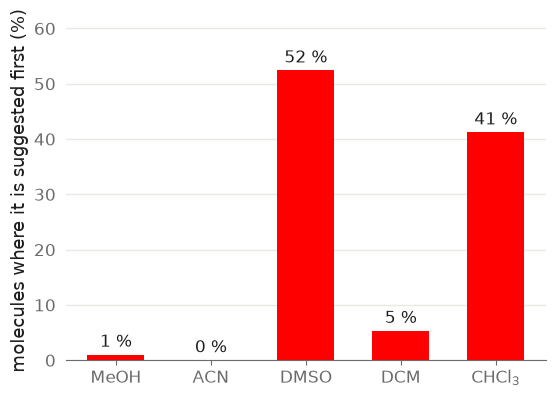

In [7]:
order = ['MeOH', 'ACN', 'DMSO', 'DCM', 'CHCl3']
distribution = pd.DataFrame({
    '% of cases': (all_choices['Solvent'].value_counts(normalize=True) * 100).reindex(order, fill_value=0).round(1),
    'Correct (%)': (all_choices.groupby('Solvent')['Correct'].mean() * 100).reindex(order).round(1),
})
display(distribution)

ps.apply()
fig, ax = plt.subplots(figsize=ps.HALF)
ax.set_ylim(0, distribution['% of cases'].max() * 1.15 + 1)
bars = ax.bar([ps.SOLVENT_LABELS[s] for s in order], distribution['% of cases'], color=ps.RED, width=0.6)
ps.label_bars(ax, bars, fmt="{:.0f} %")
ax.set_ylabel("molecules where it is suggested first (%)")
out = FIGURES / "experiments" / "top1_solvent_distribution.png"
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out)
plt.show()